# Differential geometry 2: Metrics and coordinates

*Learning path: differential geometry, part 2 of 7.* [Index](README.md) · Previous: [Curves](01-curves.ipynb) · Next: [Surfaces](03-surfaces.ipynb)

In part 1 we measured lengths of curves drawn in ordinary flat space. Now we turn it around: a **metric** is a rule
for measuring lengths *inside* a space, written in whatever coordinates we like. The metric is the central object of
differential geometry and of general relativity. You will learn

* what a line element $ds^2$ is, and how it depends on the coordinates,
* how to define a metric in Galileo, and how to get one from a change of coordinates,
* how to measure the length of a curve using only the metric,
* that some spaces, like the hyperbolic plane, have metrics that cannot come from flat space.

## 1. Pythagoras, infinitesimally

In the plane, a small step $dx$ to the right and $dy$ up covers a distance $ds$ with $ds^2 = dx^2 + dy^2$. This
*line element* is the metric. In Galileo, `metric(coordinates, matrix)` defines it; the matrix $g_{ab}$ holds the
coefficients, $ds^2 = \sum_{a,b} g_{ab}\,dx^a dx^b$.

In [1]:
flat = metric([x y], [1 0; 0 1])

$$ds^2 = \, dx^2 + \, dy^2$$

## 2. The same plane in polar coordinates

With $x = r\cos\phi$, $y = r\sin\phi$, a step $dr$ outwards covers distance $dr$, but a step $d\phi$ around covers
$r\,d\phi$: the further out, the longer the arc. So $ds^2 = dr^2 + r^2 d\phi^2$. Galileo works this out from the
coordinate change with `inducedmetric(map, coordinates)`:

In [2]:
polar = [r*cos(phi) r*sin(phi)];
inducedmetric(polar, [r phi])

$$ds^2 = \, dr^2 + r^{2}\, d\phi^2$$

The *space* is the same flat plane, but the *metric components* are different: $g_{\phi\phi} = r^2$ is not constant.
That is the first big lesson: **metric components depend on the coordinates**, so we must be careful when we ask
whether a space is curved. (Part 4 gives the coordinate-independent answer.)

Here is what the polar coordinate grid looks like. The circles are lines of constant $r$, the rays lines of constant
$\phi$:

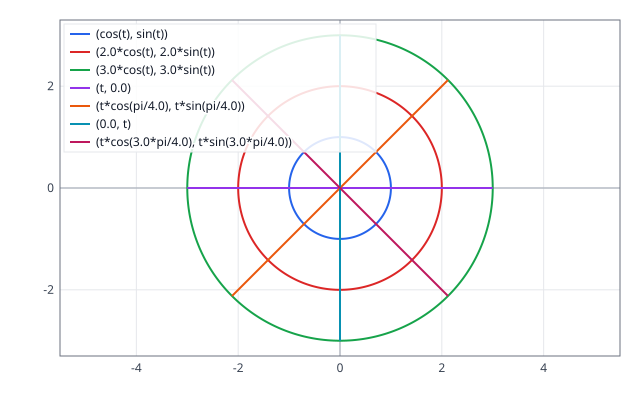

In [3]:
c1 = parametric(cos(t), sin(t), t, 0, 2*pi);
c2 = parametric(2*cos(t), 2*sin(t), t, 0, 2*pi);
c3 = parametric(3*cos(t), 3*sin(t), t, 0, 2*pi);
l1 = parametric(t, 0, t, -3, 3);
l2 = parametric(t*cos(pi/4), t*sin(pi/4), t, -3, 3);
l3 = parametric(0, t, t, -3, 3);
l4 = parametric(t*cos(3*pi/4), t*sin(3*pi/4), t, -3, 3);
show(c1, c2, c3, l1, l2, l3, l4)

### Spherical coordinates

The same works in three dimensions. Spherical coordinates $(r, \theta, \phi)$, with $\theta$ measured from the north
pole:

In [4]:
sph = [r*sin(theta)*cos(phi) r*sin(theta)*sin(phi) r*cos(theta)];
s = inducedmetric(sph, [r theta phi])

$$ds^2 = \, dr^2 + r^{2}\, d\theta^2 + r^{2} \sin^{2}\left(\theta\right)\, d\phi^2$$

Galileo also knows this one: `metric.generate(spherical)`. The ready-made metrics are `minkowski`, `euclidean`,
`polar`, `spherical`, `two-sphere`, `three-sphere`, `torus`, `hyperbolic` and `schwarzschild`.

## 3. The inverse metric

Many formulas need the inverse matrix $g^{ab}$ as well. For a diagonal metric it simply inverts each entry:

In [5]:
inverse(s)

$$g^{ab} = \begin{pmatrix} 1 & 0 & 0 \\ 0 & \frac{1}{r^{2}} & 0 \\ 0 & 0 & \frac{1}{r^{2} \sin^{2}\left(\theta\right)} \end{pmatrix}$$

## 4. Lengths from the metric

Along a curve $x^a(t)$ the length is $\int \sqrt{g_{ab}\,\dot x^a \dot x^b}\;dt$. Take a circle of latitude at polar
angle $\theta_0$ on a sphere of radius $r$: $\theta = \theta_0$ stays fixed and $\phi = t$ runs from 0 to $2\pi$. Only
$g_{\phi\phi} = r^2\sin^2\theta$ contributes, so the speed is $r\sin\theta_0$ and the length is $2\pi r\sin\theta_0$.
Numerically, on the unit sphere at $\theta_0 = \pi/3$ (latitude 30° north):

In [6]:
odesolve([sin(pi/3)], [len], t, [0], 0, 2*pi)
eval(2*pi*sin(pi/3))

5.4413980927020695
5.441398092702653

A more interesting path: a spiral on the unit sphere from the north pole to the south pole, $\theta = t$,
$\phi = 8t$ for $t$ from 0 to $\pi$. Its speed is $\sqrt{g_{\theta\theta} + g_{\phi\phi}\cdot 8^2} = \sqrt{1 + 64\sin^2 t}$:

In [7]:
odesolve([sqrt(1 + 64*sin(t)^2)], [len], t, [0], 0, pi)

16.49505746646492

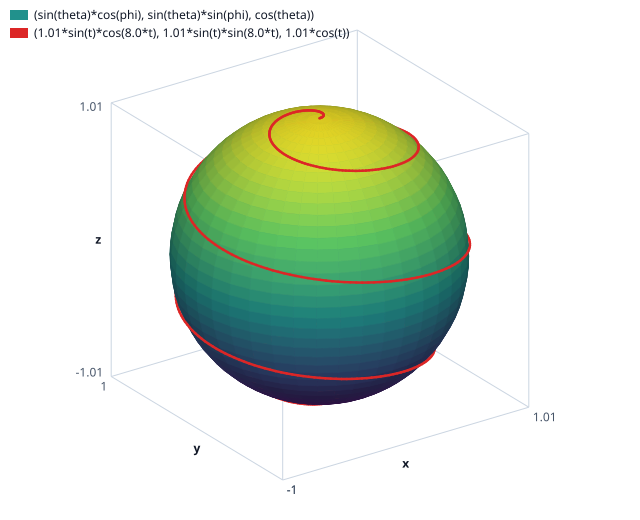

In [8]:
r = 1;
ball = surface(sin(theta)*cos(phi), sin(theta)*sin(phi), cos(theta), theta, 0, pi, phi, 0, 2*pi);
spiral = parametric3d(1.01*sin(t)*cos(8*t), 1.01*sin(t)*sin(8*t), 1.01*cos(t), t, 0, pi);
show(ball, spiral)

The spiral from pole to pole is about 16.5 long, compared with $\pi \approx 3.14$ for the direct route along a meridian.

## 5. A space that is not flat: the hyperbolic plane

Nothing forces a metric to come from flat space. The **hyperbolic plane** is the upper half plane $y > 0$ with [1]

$$ds^2 = \frac{dx^2 + dy^2}{y^2}$$

Near the $x$ axis, every step counts for a lot: the axis itself is infinitely far away.

In [9]:
clear
h = metric.generate(hyperbolic)

$$ds^2 = \frac{1}{y^{2}}\, dx^2 + \frac{1}{y^{2}}\, dy^2$$

Walking straight up from $y = 1$ to $y = Y$ takes length $\int_1^Y dy/y = \ln Y$. Walking up to $y = e$ is length 1,
and to the axis ($y \to 0$) is infinitely far:

In [10]:
odesolve([1/t], [len], t, [0], 1, e)
odesolve([1/t], [len], t, [0], 1, 0.001)

1.0000000000002671
-6.907755291680066

(The second number is negative because we walked downwards, from $t = 1$ to $t = 0.001$.) M. C. Escher's *Circle
Limit* prints (1958–1960) show this geometry in a disc [2]: all the fish are the same size in the hyperbolic metric. We will see in
part 4 that this space has curvature $-1$ everywhere, and in part 6 what straight lines look like in it.

## Summary

* A metric $g_{ab}$ gives the line element $ds^2 = g_{ab}\,dx^a dx^b$: Pythagoras for small steps.
* `metric(coords, matrix)` defines one; `inducedmetric(map, coords)` derives it from a coordinate change or an
  embedding; `metric.generate(name)` gives ready-made ones.
* Metric components depend on the coordinates; lengths do not.
* Lengths of curves follow from the metric alone.

**Try it:** define the metric of the plane in *parabolic coordinates*, $x = (u^2 - v^2)/2$, $y = uv$, with
`inducedmetric([(u^2-v^2)/2 u*v], [u v])`.

Next: [Surfaces](03-surfaces.ipynb), where the metric comes from a curved surface in space.

## Sources

Numbers in square brackets in the text refer to this list.

1. H. Poincaré, "Théorie des groupes fuchsiens", *Acta Mathematica* **1**, 1–62 (1882). [doi:10.1007/BF02592124](https://doi.org/10.1007/BF02592124)
2. H. S. M. Coxeter, "The non-Euclidean symmetry of Escher's picture 'Circle Limit III'", *Leonardo* **12**, 19–25 (1979). [doi:10.2307/1574078](https://doi.org/10.2307/1574078)
3. M. P. do Carmo, *Differential Geometry of Curves and Surfaces*, 2nd ed., Dover (2016). Chapter 2 (first fundamental form).